# Branching Fraction Plots

In [1]:
from lights.plotting import setup_style
from lights.constants import mB, mK, mKs
from lights.form_factors import aK_vals_GRDV, aKs_vals_GRDV, aK_cov_GRDV, aKs_cov_GRDV
from lights.branching_fractions import K, KS, dBdqsq_SM, dBdqsq_BKphiphi, dBdqsq_BKpsipsi, dBdqsq_BKVV, dBdqsq_BKPsiPsi

from pathlib import Path
import numpy as np
import numpy.random as npr
from scipy.integrate import quad
import matplotlib.pyplot as plt
cmap = plt.get_cmap("tab10")

from lights.paths import PLOTS_DIR
SAVE_DIR = PLOTS_DIR / "branching_fractions"

setup_style()

## $B\to K E_{\mathrm{miss}}$

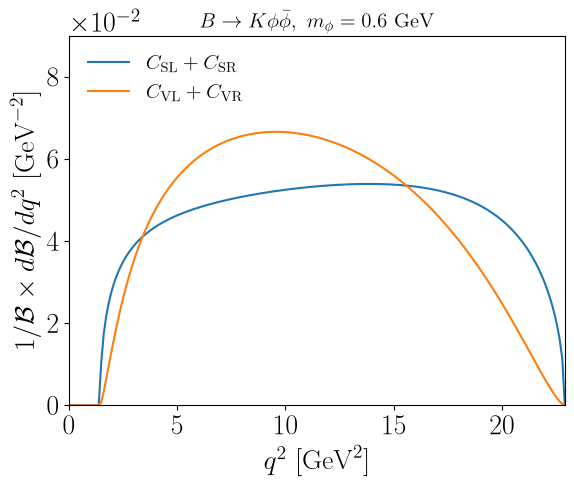

In [2]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mphi = 0.6
qsq_vals_K = np.linspace(1e-3, (mB - mK)**2, 200)

BKSS = quad(lambda qsq: dBdqsq_BKphiphi(qsq, mphi, [1.,1.,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKVV = quad(lambda qsq: dBdqsq_BKphiphi(qsq, mphi, [0,0,1.,1.])[K], 0.0001, (mB - mK)**2)[0]

leg1, = axes.plot(qsq_vals_K, dBdqsq_BKphiphi(qsq_vals_K, mphi, [1.,1.,0,0])[K]/BKSS);
leg2, = axes.plot(qsq_vals_K, dBdqsq_BKphiphi(qsq_vals_K, mphi, [0,0,1.,1.])[K]/BKVV);

axes.set_xlim(0, (mB - mK)**2);
axes.set_ylim(0.0,0.09);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1,leg2], [
    r'$C_{\rm SL} + C_{\rm SR}$',
    r'$C_{\rm VL} + C_{\rm VR}$',
    ], loc='upper left',fontsize=15,frameon=False, ncol=1);
plt.title(r'$B\to K \phi\bar{\phi}, ~ m_\phi = %1.1f~\mathrm{GeV}$' % mphi, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoK_3body_scalar.pdf", bbox_inches='tight')

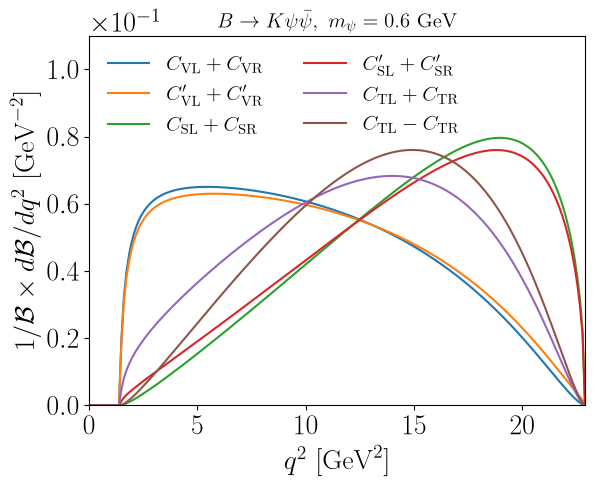

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mpsi = 0.6
qsq_vals_K = np.linspace(1e-3, (mB - mK)**2, 200)

BKVV = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [1.,1.,0,0,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKVA = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,1.,1.,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKSS = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,1.,1.,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKSP = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,1.,1.,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTT = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,0,0,1.,1.])[K], 0.0001, (mB - mK)**2)[0]
BKTtT = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,0,0,1.,-1.])[K], 0.0001, (mB - mK)**2)[0]

leg1, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [1.,1.,0,0,0,0,0,0,0,0])[K]/BKVV);
leg2, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [0,0,1.,1.,0,0,0,0,0,0])[K]/BKVA);
leg3, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [0,0,0,0,1.,1.,0,0,0,0])[K]/BKSS);
leg4, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [0,0,0,0,0,0,1.,1.,0,0])[K]/BKSP);
leg5, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [0,0,0,0,0,0,0,0,1.,1.])[K]/BKTT);
leg6, = axes.plot(qsq_vals_K, dBdqsq_BKpsipsi(qsq_vals_K, mpsi, [0,0,0,0,0,0,0,0,1.,-1.])[K]/BKTtT);

axes.set_xlim(0, (mB - mK)**2);
axes.set_ylim(0.0,0.11);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1,leg2,leg3,leg4,leg5,leg6], [
    r'$C_{\rm VL} + C_{\rm VR}$',
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$',
    r'$C_{\rm SL} + C_{\rm SR}$',
    r'$C_{\rm SL}^{\prime} + C_{\rm SR}^{\prime}$',
    r'$C_{\rm TL} + C_{\rm TR}$',
    r'$C_{\rm TL} - C_{\rm TR}$'
    ], loc='upper left',fontsize=15,frameon=False, ncol=2);
plt.title(r'$B\to K \psi\bar{\psi}, ~m_\psi = %1.1f~\mathrm{GeV}$' % mpsi, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoK_3body_fermion.pdf", bbox_inches='tight')

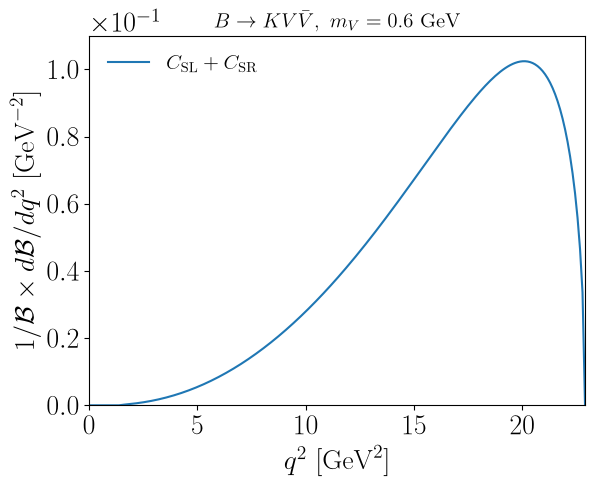

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mV = 0.6
qsq_vals_K = np.linspace(1e-3, (mB - mK)**2, 200)

BKSS = quad(lambda qsq: dBdqsq_BKVV(qsq, mV, [1.,1.])[K], 0.0001, (mB - mK)**2)[0]

leg1, = axes.plot(qsq_vals_K, dBdqsq_BKVV(qsq_vals_K, mV, [1.,1.])[K]/BKSS);

axes.set_xlim(0, (mB - mK)**2);
axes.set_ylim(0.0,0.11);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1], [
    r'$C_{\rm SL} + C_{\rm SR}$',
    ], loc='upper left',fontsize=15,frameon=False, ncol=1);
plt.title(r'$B\to K V\bar{V}, ~ m_V = %1.1f~\mathrm{GeV}$' % mV, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoK_3body_vector.pdf", bbox_inches='tight')

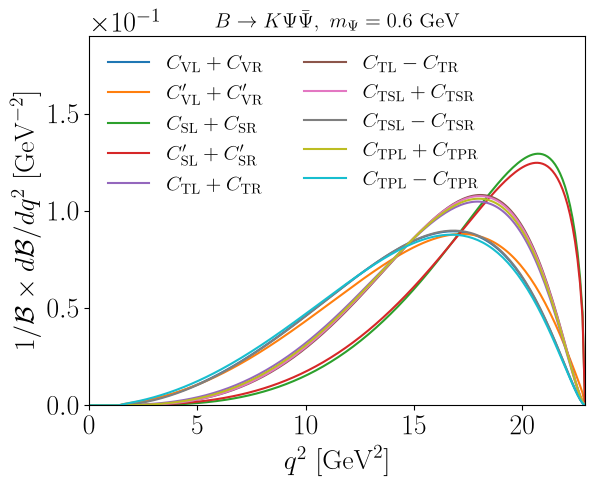

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mPsi = 0.6
qsq_vals_K = np.linspace(1e-3, (mB - mK)**2, 200)

BKVV = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [1.,1.,0,0,0,0,0,0,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKVA = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,1.,1.,0,0,0,0,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKSS = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,1.,1.,0,0,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKSP = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,1.,1.,0,0,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTT = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,1.,1.,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTtT = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,1.,-1.,0,0,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTS = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,0,0,1.,1.,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTtS = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,0,0,1.,-1.,0,0])[K], 0.0001, (mB - mK)**2)[0]
BKTP = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,0,0,0,0,1.,1.])[K], 0.0001, (mB - mK)**2)[0]
BKTtP = quad(lambda qsq: dBdqsq_BKPsiPsi(qsq, mPsi, [0,0,0,0,0,0,0,0,0,0,0,0,1.,-1.])[K], 0.0001, (mB - mK)**2)[0]

leg1, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [1.,1.,0,0,0,0,0,0,0,0,0,0,0,0])[K]/BKVV);
leg2, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,1.,1.,0,0,0,0,0,0,0,0,0,0])[K]/BKVA);
leg3, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,1.,1.,0,0,0,0,0,0,0,0])[K]/BKSS);
leg4, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,1.,1.,0,0,0,0,0,0])[K]/BKSP);
leg5, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,1.,1.,0,0,0,0])[K]/BKTT);
leg6, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,1.,-1.,0,0,0,0])[K]/BKTtT);
leg7, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,0,0,1.,1.,0,0])[K]/BKTS);
leg8, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,0,0,1.,-1.,0,0])[K]/BKTtS);
leg9, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,0,0,0,0,1.,1.])[K]/BKTP);
leg10, = axes.plot(qsq_vals_K, dBdqsq_BKPsiPsi(qsq_vals_K, mPsi, [0,0,0,0,0,0,0,0,0,0,0,0,1.,-1.])[K]/BKTtP);

axes.set_xlim(0, (mB - mK)**2);
axes.set_ylim(0.0,0.19);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1,leg2,leg3,leg4,leg5,leg6,leg7,leg8,leg9,leg10], [
    r'$C_{\rm VL} + C_{\rm VR}$',
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$',
    r'$C_{\rm SL} + C_{\rm SR}$',
    r'$C_{\rm SL}^{\prime} + C_{\rm SR}^{\prime}$',
    r'$C_{\rm TL} + C_{\rm TR}$',
    r'$C_{\rm TL} - C_{\rm TR}$',
    r'$C_{\rm TSL} + C_{\rm TSR}$',
    r'$C_{\rm TSL} - C_{\rm TSR}$',
    r'$C_{\rm TPL} + C_{\rm TPR}$',
    r'$C_{\rm TPL} - C_{\rm TPR}$'
    ], loc='upper left',fontsize=15,frameon=False, ncol=2);
plt.title(r'$B\to K \Psi\bar{\Psi}, ~m_\Psi = %1.1f~\mathrm{GeV}$' % mPsi, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoK_3body_spin32.pdf", bbox_inches='tight')

## $B\to K^{*} E_{\mathrm{miss}}$

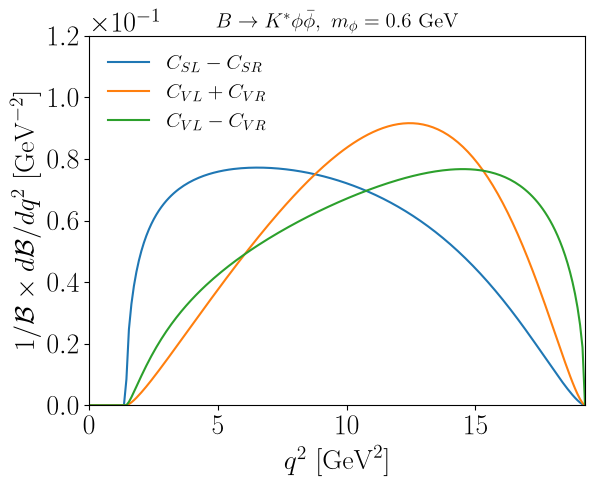

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mphi = 0.6
qsq_vals_Ks = np.linspace(1e-3, (mB - mKs)**2, 200)

BKsPS = quad(lambda qsq: dBdqsq_BKphiphi(qsq, mphi, [1.,-1.,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsVV = quad(lambda qsq: dBdqsq_BKphiphi(qsq, mphi, [0,0,1.,1.])[KS], 0.0001, (mB - mKs)**2)[0]
BKsAV = quad(lambda qsq: dBdqsq_BKphiphi(qsq, mphi, [0,0,1.,-1.])[KS], 0.0001, (mB - mKs)**2)[0]

leg1, = axes.plot(qsq_vals_Ks, dBdqsq_BKphiphi(qsq_vals_Ks, mphi, [1.,-1.,0,0])[KS]/BKsPS);
leg2, = axes.plot(qsq_vals_Ks, dBdqsq_BKphiphi(qsq_vals_Ks, mphi, [0,0,1.,1.])[KS]/BKsVV);
leg3, = axes.plot(qsq_vals_Ks, dBdqsq_BKphiphi(qsq_vals_Ks, mphi, [0,0,1.,-1.])[KS]/BKsAV);

axes.set_xlim(0, (mB - mKs)**2);
axes.set_ylim(0.0,0.12);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1,leg2,leg3], [
    r'$C_{SL} - C_{SR}$',
    r'$C_{VL} + C_{VR}$',
    r'$C_{VL} - C_{VR}$'
    ], loc='upper left',fontsize=15,frameon=False, ncol=1);
plt.title(r'$B\to K^* \phi\bar{\phi},~m_\phi = %1.1f~\mathrm{GeV}$' % mphi, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoKs_3body_scalar.pdf", bbox_inches='tight')

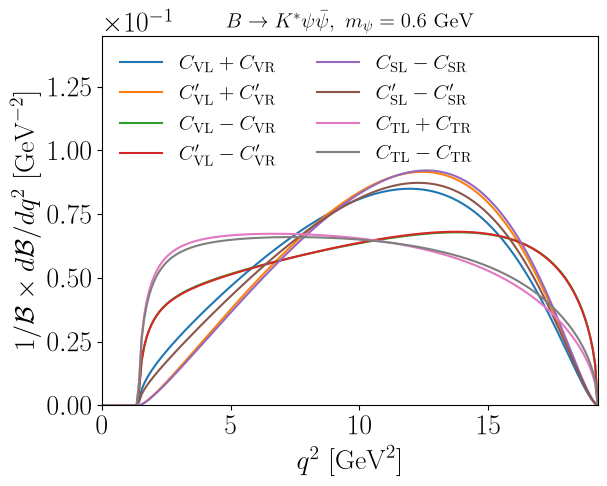

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mpsi = 0.6
qsq_vals_Ks = np.linspace(1e-3, (mB - mKs)**2, 200)

BKsVV = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [1.,1.,0,0,0,0,0,0,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsVA = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,1.,1.,0,0,0,0,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsAV = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [1.,-1.,0,0,0,0,0,0,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsAA = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,1.,-1.,0,0,0,0,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsPS = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,1.,-1.,0,0,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsPP = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,1.,-1.,0,0])[KS], 0.0001, (mB - mKs)**2)[0]
BKsTT = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,0,0,1.,1.])[KS], 0.0001, (mB - mKs)**2)[0]
BKsTtT = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, mpsi, [0,0,0,0,0,0,0,0,1.,-1.])[KS], 0.0001, (mB - mKs)**2)[0]

leg1, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [1.,1.,0,0,0,0,0,0,0,0])[KS]/BKsVV);
leg2, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,1.,1.,0,0,0.,0.,0,0])[KS]/BKsVA);
leg3, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [1.,-1.,0,0,0,0,0.,0.,0,0])[KS]/BKsAV);
leg4, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,1.,-1.,0,0,0.,0.,0,0])[KS]/BKsAA);
leg5, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,0,0,1.,-1.,0.,0.,0,0])[KS]/BKsPS);
leg6, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,0,0,0,0,1.,-1.,0,0])[KS]/BKsPP);
leg7, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,0,0,0,0,0,0,1.,1.])[KS]/BKsTT);
leg8, = axes.plot(qsq_vals_Ks, dBdqsq_BKpsipsi(qsq_vals_Ks, mpsi, [0,0,0,0,0,0,0,0,1.,-1.])[KS]/BKsTtT);

axes.set_xlim(0, (mB - mKs)**2);
axes.set_ylim(0.0,0.145);

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$');

axes.legend([leg1,leg2,leg3,leg4,leg5,leg6,leg7,leg8], [
    r'$C_{\rm VL} + C_{\rm VR}$',
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$',
    r'$C_{\rm VL} - C_{\rm VR}$',
    r'$C_{\rm VL}^{\prime} - C_{\rm VR}^{\prime}$',
    r'$C_{\rm SL} - C_{\rm SR}$',
    r'$C_{\rm SL}^{\prime} - C_{\rm SR}^{\prime}$',
    r'$C_{\rm TL} + C_{\rm TR}$',
    r'$C_{\rm TL} - C_{\rm TR}$'
    ], loc='upper left',fontsize=15,frameon=False, ncol=2);
plt.title(r'$B\to K^* \psi\bar{\psi},~m_\psi = %1.1f~\mathrm{GeV}$' % mpsi, fontsize = 15);
plt.savefig(SAVE_DIR / "BtoKs_3body_fermion.pdf", bbox_inches='tight')